Device: cpu
Models loaded successfully.


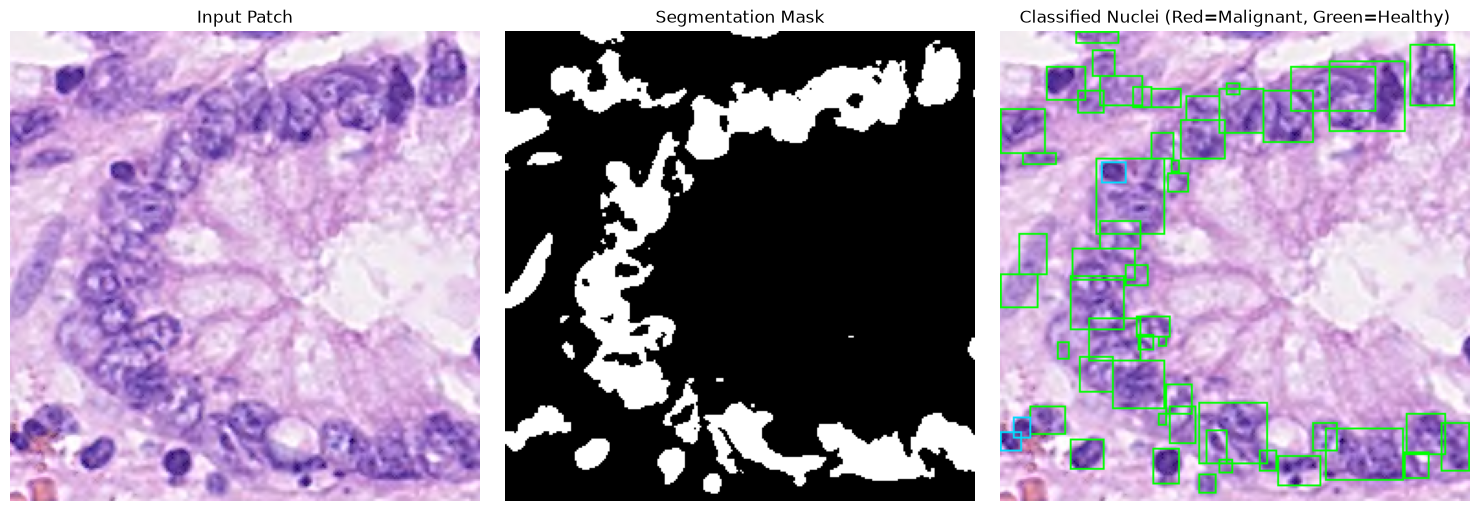

In [3]:
import glob
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# 1. Model Definitions
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.conv_up1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up3 = DoubleConv(128, 64)
        self.up4 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up4 = DoubleConv(64, 32)
        self.outc = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.conv_up1(torch.cat([self.up1(x5), x4], dim=1))
        x = self.conv_up2(torch.cat([self.up2(x), x3], dim=1))
        x = self.conv_up3(torch.cat([self.up3(x), x2], dim=1))
        x = self.conv_up4(torch.cat([self.up4(x), x1], dim=1))
        return self.outc(x)

class NucleiClassifier(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

# 2. Check and Load Model Weights
unet_path = "models/unet.pth"
cls_path = "models/classifier.pth"

if not os.path.exists(unet_path):
    raise FileNotFoundError(f"Model path '{unet_path}' not found. Please train U-Net first.")
if not os.path.exists(cls_path):
    raise FileNotFoundError(f"Classifier path '{cls_path}' not found. Please train classifier first.")

unet = UNet().to(device)
unet.load_state_dict(torch.load(unet_path, map_location=device, weights_only=True))
unet.eval()

clf = NucleiClassifier().to(device)
clf.load_state_dict(torch.load(cls_path, map_location=device, weights_only=True))
clf.eval()
print("Models loaded successfully.")

# 3. Load Sample Test Image
test_imgs = sorted(glob.glob("dataset/processed/test/images/*.png"))
if not test_imgs:
    test_imgs = sorted(glob.glob("dataset/**/Test/Images/*.png", recursive=True))
if not test_imgs:
    test_imgs = sorted(glob.glob("dataset/MoNuSeg_test/images/*.png"))
if not test_imgs:
    raise FileNotFoundError("No test images found in the dataset directory.")

img_bgr = cv2.imread(test_imgs[0])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_256 = cv2.resize(img_rgb, (256, 256))

# 4. Step 1: Segmentation
t_in = (
    torch.tensor(
        np.transpose(img_256.astype(np.float32) / 255.0, (2, 0, 1)),
        dtype=torch.float32,
    )
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():
    prob = torch.sigmoid(unet(t_in)).squeeze().cpu().numpy()

prob_u8 = (prob * 255).astype(np.uint8)
_, binary_mask = cv2.threshold(prob_u8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Step 2: Watershed Separation for Touching Cells
dist = cv2.distanceTransform((binary_mask * 255).astype(np.uint8), cv2.DIST_L2, 5)
coords = peak_local_max(dist, min_distance=5, labels=binary_mask)

mask_peaks = np.zeros(dist.shape, dtype=bool)
if len(coords) > 0:
    mask_peaks[tuple(coords.T)] = True
markers, _ = ndimage.label(mask_peaks)
inst_map = watershed(-dist, markers, mask=binary_mask)

# 6. Step 3: CNN Classification with Normalization
class_colors = {
    0: (128, 128, 128),  # Other: Gray
    1: (0, 220, 255),    # Inflammatory: Cyan
    2: (0, 255, 0),      # Healthy: Green
    3: (255, 0, 0),      # Malignant: Red
    4: (255, 140, 0),    # Misc: Orange
}
class_names = {
    0: "Other",
    1: "Inflammatory",
    2: "Healthy",
    3: "Malignant",
    4: "Misc",
}

# ImageNet normalization parameters
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

overlay = img_256.copy()
detected_counts = {name: 0 for name in class_names.values()}

for lbl in np.unique(inst_map):
    if lbl == 0:
        continue
    cell_mask = inst_map == lbl
    if np.sum(cell_mask) < 20:
        continue

    ys, xs = np.where(cell_mask)
    y1, y2 = max(0, int(ys.min()) - 2), min(256, int(ys.max()) + 2)
    x1, x2 = max(0, int(xs.min()) - 2), min(256, int(xs.max()) + 2)

    if y2 - y1 < 4 or x2 - x1 < 4:
        continue

    cell_patch = img_256[y1:y2, x1:x2]
    crop = cv2.resize(cell_patch, (32, 32)).astype(np.float32) / 255.0
    
    # Normalized tensor matching training transforms
    crop_norm = (crop - mean) / std
    crop_t = (
        torch.tensor(np.transpose(crop_norm, (2, 0, 1)), dtype=torch.float32)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():
        logits = clf(crop_t)
        c_id = logits.argmax(dim=1).item()

    detected_counts[class_names[c_id]] += 1
    cv2.rectangle(
        overlay,
        (int(xs.min()), int(ys.min())),
        (int(xs.max()), int(ys.max())),
        class_colors[c_id],
        1,
    )

# 7. Step 4: Visual Output and Reporting
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_256)
ax[0].set_title("Input Patch")
ax[0].axis("off")

ax[1].imshow(binary_mask, cmap="gray")
ax[1].set_title("Segmentation Mask")
ax[1].axis("off")

ax[2].imshow(overlay)
ax[2].set_title("Classified Nuclei (Red=Malignant, Green=Healthy)")
ax[2].axis("off")

plt.tight_layout()

device: cpu
dono models load ho gaye!


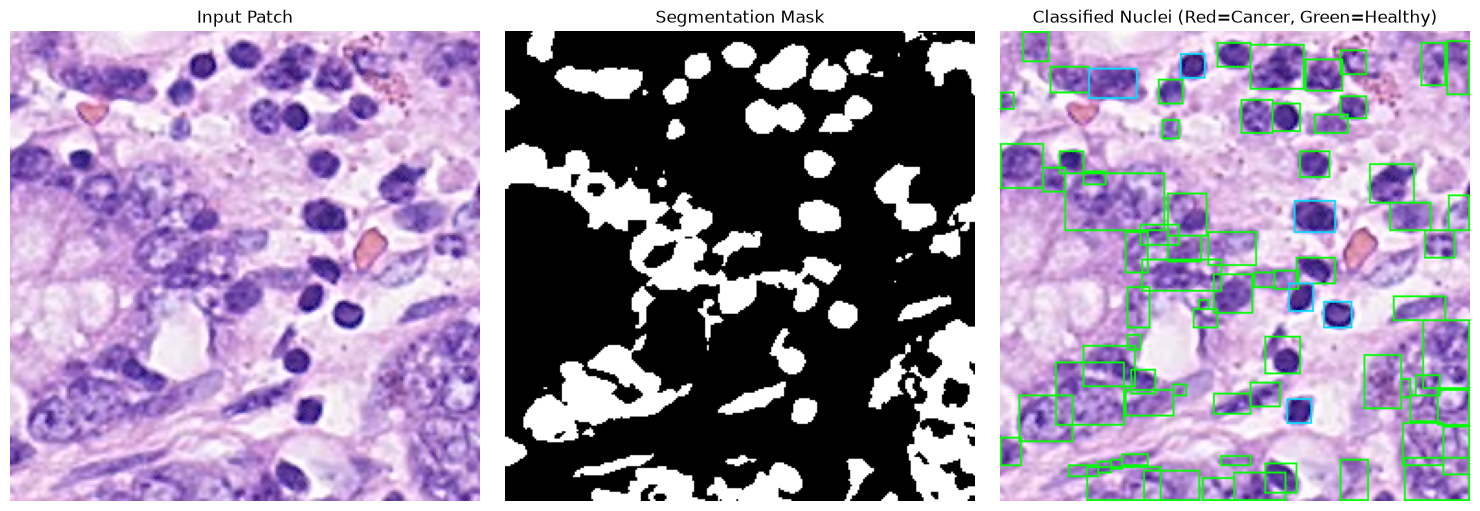


--- Summary Report ---
Other: 0 cells
Inflammatory: 6 cells
Healthy: 70 cells
Malignant: 0 cells
Misc: 0 cells


In [7]:
import glob
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

# 1. models architecture
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.conv_up1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up3 = DoubleConv(128, 64)
        self.up4 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up4 = DoubleConv(64, 32)
        self.outc = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.conv_up1(torch.cat([self.up1(x5), x4], dim=1))
        x = self.conv_up2(torch.cat([self.up2(x), x3], dim=1))
        x = self.conv_up3(torch.cat([self.up3(x), x2], dim=1))
        x = self.conv_up4(torch.cat([self.up4(x), x1], dim=1))
        return self.outc(x)

class NucleiClassifier(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

# 2. weights load karein
unet_path = "models/unet.pth"
cls_path = "models/classifier.pth"

unet = UNet().to(device)
unet.load_state_dict(torch.load(unet_path, map_location=device, weights_only=True))
unet.eval()

clf = NucleiClassifier().to(device)
clf.load_state_dict(torch.load(cls_path, map_location=device, weights_only=True))
clf.eval()
print("dono models load ho gaye!")

# 3. test image load karein
test_imgs = sorted(glob.glob("dataset/processed/test/images/*.png"))
if not test_imgs:
    test_imgs = sorted(glob.glob("dataset/**/Test/Images/*.png", recursive=True))
if not test_imgs:
    test_imgs = sorted(glob.glob("dataset/MoNuSeg_test/images/*.png"))

img_bgr = cv2.imread(test_imgs[4])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_256 = cv2.resize(img_rgb, (256, 256))

# 4. u-net segmentation
t_in = torch.tensor(
    np.transpose(img_256.astype(np.float32) / 255.0, (2, 0, 1)),
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    prob = torch.sigmoid(unet(t_in)).squeeze().cpu().numpy()

binary_mask = (prob > 0.45).astype(np.uint8)

# 5. watershed touches separation
dist = cv2.distanceTransform((binary_mask * 255).astype(np.uint8), cv2.DIST_L2, 5)
coords = peak_local_max(dist, min_distance=6, labels=binary_mask)

mask_peaks = np.zeros(dist.shape, dtype=bool)
if len(coords) > 0:
    mask_peaks[tuple(coords.T)] = True
markers, _ = ndimage.label(mask_peaks)
inst_map = watershed(-dist, markers, mask=binary_mask)

# 6. cnn classification with proper transforms
class_colors = {
    0: (128, 128, 128),  # other (gray)
    1: (0, 220, 255),    # inflammatory (cyan)
    2: (0, 255, 0),      # healthy (green)
    3: (255, 0, 0),      # malignant (red)
    4: (255, 140, 0),    # misc (orange)
}
class_names = {
    0: "Other",
    1: "Inflammatory",
    2: "Healthy",
    3: "Malignant",
    4: "Misc",
}

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

overlay = img_256.copy()
detected_counts = {name: 0 for name in class_names.values()}

for lbl in np.unique(inst_map):
    if lbl == 0:
        continue
    cell_mask = inst_map == lbl
    if np.sum(cell_mask) < 25:
        continue

    ys, xs = np.where(cell_mask)
    y1, y2 = max(0, int(ys.min()) - 2), min(256, int(ys.max()) + 2)
    x1, x2 = max(0, int(xs.min()) - 2), min(256, int(xs.max()) + 2)

    if y2 - y1 < 4 or x2 - x1 < 4:
        continue

    crop = cv2.resize(img_256[y1:y2, x1:x2], (32, 32)).astype(np.float32) / 255.0
    crop_norm = (crop - mean) / std
    crop_t = torch.tensor(
        np.transpose(crop_norm, (2, 0, 1)), dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = clf(crop_t)
        c_id = logits.argmax(dim=1).item()

    detected_counts[class_names[c_id]] += 1
    cv2.rectangle(
        overlay,
        (int(xs.min()), int(ys.min())),
        (int(xs.max()), int(ys.max())),
        class_colors[c_id],
        1,
    )

# 7. output visual and report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_256)
ax[0].set_title("Input Patch")
ax[0].axis("off")

ax[1].imshow(binary_mask, cmap="gray")
ax[1].set_title("Segmentation Mask")
ax[1].axis("off")

ax[2].imshow(overlay)
ax[2].set_title("Classified Nuclei (Red=Cancer, Green=Healthy)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

print("\n--- Summary Report ---")
for k, v in detected_counts.items():
    print(f"{k}: {v} cells")